<a href="https://colab.research.google.com/github/sanikanehra/MedViTV2-Implementation/blob/main/CV_Final_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Tue Oct 27 17:32:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install "natten==0.21.6+torch2110cu130" -f https://whl.natten.org

Looking in links: https://whl.natten.org
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.5/188.5 MB 30.4 MB/s  0:00:06


In [3]:
import torch
import sys

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Python:", sys.version.split()[0])
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

PyTorch: 2.11.0+cu130
CUDA: 13.0
Python: 3.13.16
GPU: Tesla T4


In [5]:
%cd /content
!git clone https://github.com/Omid-Nejati/MedViTV2.git
%cd /content/MedViTV2

/content
Cloning into 'MedViTV2'...
remote: Enumerating objects: 208, done.
remote: Counting objects: 100% (96/96), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 208 (delta 64), reused 27 (delta 26), pack-reused 112 (from 1)
Receiving objects: 100% (208/208), 3.88 MiB | 26.68 MiB/s, done.
Resolving deltas: 100% (76/76), done.
/content/MedViTV2


In [6]:
!pip install -r requirements.txt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=761261ea545851e5156fcaf77029d1bd108505603643c30bc23acfb26c7b2738
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=54a89d4477f3265293a46f401b79b1cadda7c8a8db94c48d18839b0c9660ba03
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.

In [17]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import argparse
import requests
import timm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

import torchvision.utils
from torchvision import models
import torchvision.datasets as dsets
import torchvision.transforms as transforms
from torchsummary import summary
from datasets import build_dataset
from distutils.util import strtobool
from tqdm import tqdm
import medmnist
from medmnist import INFO, Evaluator
from timm.data.constants import IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD
import natten
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize
from MedViT import MedViT_tiny, MedViT_small, MedViT_base, MedViT_large
#from MedViTV1 import MedViT_small, MedViT_base, MedViT_large


model_classes = {
    'MedViT_tiny': MedViT_tiny,
    'MedViT_small': MedViT_small,
    'MedViT_base': MedViT_base,
    'MedViT_large': MedViT_large
}

model_urls = {
    "MedViT_tiny": "https://dl.dropbox.com/scl/fi/496jbihqp360jacpji554/MedViT_tiny.pth?rlkey=6hb9froxugvtg8l639jmspxfv&st=p9ef06j8&dl=0",
    "MedViT_small": "https://dl.dropbox.com/scl/fi/6nnec8hxcn5da6vov7h2a/MedViT_small.pth?rlkey=yf5twra1cv6ep2oqr79tbzyg5&st=rwx5hy8z&dl=0",
    "MedViT_base": "https://dl.dropbox.com/scl/fi/q5c0u515dd4oc8j55bhi9/MedViT_base.pth?rlkey=5duw3uomnsyjr80wykvedjhas&st=incconx4&dl=0",
    "MedViT_large": "https://dl.dropbox.com/scl/fi/owujijpsl6vwd481hiydd/MedViT_large.pth?rlkey=cx9lqb4a1288nv4xlmux13zoe&st=kcehwbrb&dl=0"
}

def download_checkpoint(url, path):
    print(f"Downloading checkpoint from {url}...")
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        with open(path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                        f.write(chunk)
    print(f"Checkpoint downloaded and saved to {path}")

# Define the MNIST training routine
def train_mnist(epochs, net, train_loader, test_loader, optimizer, scheduler, loss_function, device, save_path, data_flag, task):
    best_acc = 0.0
    for epoch in range(epochs):
        net.train()
        running_loss = 0.0
        train_bar = tqdm(train_loader, file=sys.stdout)
        for step, datax in enumerate(train_bar):
            images, labels = datax
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(images)

            if task == 'multi-label, binary-class':
                labels = labels.to(torch.float32)
                loss = loss_function(outputs, labels)
            else:
                labels = labels.squeeze().long()
                loss = loss_function(outputs.squeeze(0), labels)

            loss.backward()
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()

            train_bar.desc = f"train epoch[{epoch + 1}/{epochs}] loss:{loss:.3f}"

        net.eval()
        y_score = torch.tensor([])
        with torch.no_grad():
            val_bar = tqdm(test_loader, file=sys.stdout)
            for val_data in val_bar:
                inputs, targets = val_data
                outputs = net(inputs.to(device))

                if task == 'multi-label, binary-class':
                    targets = targets.to(torch.float32)
                    outputs = outputs.softmax(dim=-1)
                else:
                    targets = targets.squeeze().long()
                    outputs = outputs.softmax(dim=-1)
                    targets = targets.float().resize_(len(targets), 1)

                y_score = torch.cat((y_score, outputs.cpu()), 0)

        y_score = y_score.detach().numpy()
        evaluator = Evaluator(data_flag, 'test', size=224, root='./data')
        metrics = evaluator.evaluate(y_score)

        val_accurate, _ = metrics
        print(f'[epoch {epoch + 1}] train_loss: {running_loss / len(train_loader):.3f}  auc: {metrics[0]:.3f}  acc: {metrics[1]:.3f}')
        #print(f'lr: {scheduler.get_last_lr()[-1]:.8f}')
        if val_accurate > best_acc:
            print('\nSaving checkpoint...')
            best_acc = val_accurate
            state = {
                'model': net.state_dict(),
                'optimizer': optimizer.state_dict(),
                'lr_scheduler': scheduler.state_dict(),
                'acc': best_acc,
                'epoch': epoch,
            }
            torch.save(state, save_path)

    print('Finished Training')

# Define the non-MNIST training routine
def specificity_per_class(conf_matrix):
    """Calculates specificity for each class."""
    specificity = []
    for i in range(len(conf_matrix)):
        tn = conf_matrix.sum() - (conf_matrix[i, :].sum() + conf_matrix[:, i].sum() - conf_matrix[i, i])
        fp = conf_matrix[:, i].sum() - conf_matrix[i, i]
        specificity.append(tn / (tn + fp))
    return specificity

def overall_accuracy(conf_matrix):
    """Calculates overall accuracy for multi-class."""
    tp_tn_sum = conf_matrix.trace()  # Sum of all diagonal elements (TP for all classes)
    total_sum = conf_matrix.sum()  # Sum of all elements in the matrix
    return tp_tn_sum / total_sum

def train_other(epochs, net, train_loader, test_loader, optimizer, scheduler, loss_function, device, save_path):
    best_acc = 0.0

    for epoch in range(epochs):
        net.train()
        running_loss = 0.0
        train_bar = tqdm(train_loader, file=sys.stdout)

        # Training Loop
        for step, datax in enumerate(train_bar):
            images, labels = datax
            optimizer.zero_grad()
            outputs = net(images.to(device))
            loss = loss_function(outputs, labels.to(device))
            loss.backward()
            optimizer.step()
            scheduler.step()
            running_loss += loss.item()

            train_bar.desc = f"train epoch[{epoch + 1}/{epochs}] loss:{loss:.3f}"

        # Validation Loop
        net.eval()
        all_preds = []
        all_labels = []
        all_probs = []  # Store raw probabilities/logits for AUC
        acc = 0.0

        with torch.no_grad():
            val_bar = tqdm(test_loader, file=sys.stdout)
            for val_data in val_bar:
                val_images, val_labels = val_data
                outputs = net(val_images.to(device))  # Raw outputs (logits)
                probs = torch.softmax(outputs, dim=1)  # Convert to probabilities

                predict_y = torch.max(probs, dim=1)[1]  # Predicted class

                # Collect predictions, labels, and probabilities
                all_preds.extend(predict_y.cpu().numpy())
                all_labels.extend(val_labels.cpu().numpy())
                all_probs.extend(probs.cpu().numpy())

                # Calculate accuracy
                acc += torch.eq(predict_y, val_labels.to(device)).sum().item()

        # Calculate metrics
        val_accurate = acc / len(test_loader.dataset)
        precision = precision_score(all_labels, all_preds, average='weighted')
        recall = recall_score(all_labels, all_preds, average='weighted')  # Sensitivity
        f1 = f1_score(all_labels, all_preds, average='weighted')

        # Confusion Matrix for multi-class
        conf_matrix = confusion_matrix(all_labels, all_preds)
        specificity = specificity_per_class(conf_matrix)  # List of specificities per class
        avg_specificity = sum(specificity) / len(specificity)  # Average specificity

        # Overall Accuracy calculation
        overall_acc = overall_accuracy(conf_matrix)

        # One-hot encode the labels for AUC calculation
        n_classes = len(conf_matrix)
        all_labels_one_hot = label_binarize(all_labels, classes=list(range(n_classes)))

        try:
            # Compute AUC for multi-class
            auc = roc_auc_score(all_labels_one_hot, all_probs, multi_class='ovr')
        except ValueError:
            auc = float('nan')  # Handle edge case where AUC can't be computed

        # Print metrics
        print(f'[epoch {epoch + 1}] train_loss: {running_loss / len(train_loader):.3f} '
              f'val_accuracy: {val_accurate:.4f} precision: {precision:.4f} '
              f'recall: {recall:.4f} specificity: {avg_specificity:.4f} '
              f'f1_score: {f1:.4f} auc: {auc:.4f} overall_accuracy: {overall_acc:.4f}')

        #print(f'lr: {scheduler.get_last_lr()[-1]:.8f}')

        # Save best model
        if val_accurate > best_acc:
            print('\nSaving checkpoint...')
            best_acc = val_accurate
            state = {
                'model': net.state_dict(),
                'optimizer': optimizer.state_dict(),
                'lr_scheduler': scheduler.state_dict(),
                'acc': best_acc,
                'epoch': epoch,
            }
            torch.save(state, save_path)

    print('Finished Training')

def main(args):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print("Using {} device.".format(device))
    model_name = args.model_name
    dataset_name = args.dataset
    pretrained = args.pretrained
    if args.dataset.endswith('mnist'):
        info = INFO[args.dataset]
        task = info['task']
        if task == "multi-label, binary-class":
            loss_function = nn.BCEWithLogitsLoss()
        else:
            loss_function = nn.CrossEntropyLoss()
    else:
        loss_function = nn.CrossEntropyLoss()
    model_class = model_classes.get(model_name)

    batch_size = args.batch_size
    lr = args.lr

    train_dataset, test_dataset, nb_classes = build_dataset(args=args)
    val_num = len(test_dataset)
    train_num = len(train_dataset)

    # scheduler max iteration
    eta = args.epochs * train_num // args.batch_size

    # Select model
    if model_name in model_classes:
        model_class = model_classes[model_name]
        net = model_class(num_classes=nb_classes).cuda()
        if pretrained:
            checkpoint_path = args.checkpoint_path
            if not os.path.exists(checkpoint_path):
                checkpoint_url = model_urls.get(model_name)
                if not checkpoint_url:
                    raise ValueError(f"Checkpoint URL for model {model_name} not found.")
                download_checkpoint(checkpoint_url, f'./{model_name}.pth')
                checkpoint_path = f'./{model_name}.pth'

            checkpoint = torch.load(checkpoint_path)
            state_dict = net.state_dict()
            for k in ['proj_head.0.weight', 'proj_head.0.bias']:
                if k in checkpoint and checkpoint[k].shape != state_dict[k].shape:
                    print(f"Removing key {k} from pretrained checkpoint")
                    del checkpoint[k]
            net.load_state_dict(checkpoint, strict=False)
    else:
        net = timm.create_model(model_name, pretrained=pretrained, num_classes=nb_classes).cuda()


    optimizer = optim.AdamW(net.parameters(), lr=lr, betas=[0.9, 0.999], weight_decay=0.05)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=eta, eta_min=5e-6)

    train_loader = data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = data.DataLoader(dataset=test_dataset, batch_size=2*batch_size, shuffle=False)

    print(train_dataset)
    print("===================")
    print(test_dataset)

    epochs = args.epochs
    best_acc = 0.0
    save_path = f'./{model_name}_{dataset_name}.pth'
    train_steps = len(train_loader)

    if dataset_name.endswith('mnist'):

        train_mnist(epochs, net, train_loader, test_loader,
        optimizer, scheduler, loss_function, device, save_path, dataset_name, task)
    else:
        train_other(epochs, net, train_loader, test_loader,
        optimizer, scheduler, loss_function, device, save_path)


if __name__ == '__main__':
    parser = argparse.ArgumentParser(description='Training script for MedViT models.')
    parser.add_argument('--model_name', type=str, default='MedViT_tiny', help='Model name to use.')
    #tissuemnist, pathmnist, chestmnist, dermamnist, octmnist, pneumoniamnist, retinamnist, breastmnist, bloodmnist,
    #organamnist, organcmnist, organsmnist'
    parser.add_argument('--dataset', type=str, default='dermamnist', help='Dataset to use.')
    parser.add_argument('--batch_size', type=int, default=24, help='Batch size for training.')
    parser.add_argument('--lr', type=float, default=0.0001, help='Learning rate.')
    parser.add_argument('--epochs', type=int, default=10, help='Number of training epochs.')
    parser.add_argument('--pretrained', type=lambda x: bool(strtobool(x)), default=False, help="Whether to use pretrained weights (True/False).")
    parser.add_argument('--checkpoint_path', type=str, default='./checkpoint/MedViT_tiny.pth', help='Path to the checkpoint file.')

    args, unknown = parser.parse_known_args()
    main(args)

Using cuda:0 device.
Number of channels:  3
Number of classes:  7


100%|██████████| 1.09G/1.09G [07:31<00:00, 2.42MB/s]


initialize_weights...
Dataset DermaMNIST of size 224 (dermamnist_224)
    Number of datapoints: 7007
    Root location: ./data
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'}
    Number of samples: {'train': 7007, 'val': 1003, 'test': 2005}
    Description: The DermaMNIST is based on the HAM10000, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. The dataset consists of 10,015 dermatoscopic images categorized as 7 different diseases, formulized as a multi-class classification task. We split the images into training, validation and test set with a ratio of 7:1:2. The source images of 3×600×450 are resized into 3×28×28.
    License: CC BY-NC 4.0
Dataset DermaMNIST of size 224 (dermamnist_224)
    Nu

In [18]:
%cd /content/MedViTV2
!python main.py --model_name 'MedViT_tiny' --dataset 'breastmnist' --pretrained False --epochs 50 2>&1 | tee logs/breast_medvit_tiny.txt

/content/MedViTV2
tee: logs/breast_medvit_tiny.txt: No such file or directory
Using cuda:0 device.
Number of channels:  1
Number of classes:  2
100%|██████████| 30.9M/30.9M [00:31<00:00, 978kB/s] 
initialize_weights...
Dataset BreastMNIST of size 224 (breastmnist_224)
    Number of datapoints: 546
    Root location: ./data
    Split: train
    Task: binary-class
    Number of channels: 1
    Meaning of labels: {'0': 'malignant', '1': 'normal, benign'}
    Number of samples: {'train': 546, 'val': 78, 'test': 156}
    Description: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images of 1×500×500 are resized into 1×28×28.
    Li

In [19]:
%cd /content/MedViTV2
!python main.py --model_name 'resnet34' --dataset 'breastmnist' --pretrained True --epochs 50 2>&1 | tee logs/breast_resnet34.txt

/content/MedViTV2
tee: logs/breast_resnet34.txt: No such file or directory
Using cuda:0 device.
Number of channels:  1
Number of classes:  2
Dataset BreastMNIST of size 224 (breastmnist_224)
    Number of datapoints: 546
    Root location: ./data
    Split: train
    Task: binary-class
    Number of channels: 1
    Meaning of labels: {'0': 'malignant', '1': 'normal, benign'}
    Number of samples: {'train': 546, 'val': 78, 'test': 156}
    Description: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images of 1×500×500 are resized into 1×28×28.
    License: CC BY 4.0
Dataset BreastMNIST of size 224 (breastmnist_224)
    Number 

In [20]:
%cd /content/MedViTV2
!python main.py --model_name 'resnet34' --dataset 'dermamnist' --pretrained True --epochs 10 2>&1 | tee logs/derma_resnet34.txt

/content/MedViTV2
tee: logs/derma_resnet34.txt: No such file or directory
Using cuda:0 device.
Number of channels:  3
Number of classes:  7
Dataset DermaMNIST of size 224 (dermamnist_224)
    Number of datapoints: 7007
    Root location: ./data
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'}
    Number of samples: {'train': 7007, 'val': 1003, 'test': 2005}
    Description: The DermaMNIST is based on the HAM10000, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. The dataset consists of 10,015 dermatoscopic images categorized as 7 different diseases, formulized as a multi-class classification task. We split the images into training, validation and test set with a ratio of 7:1:2. The source images o

Number of channels:  3
Number of classes:  7


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


initialize_weights...


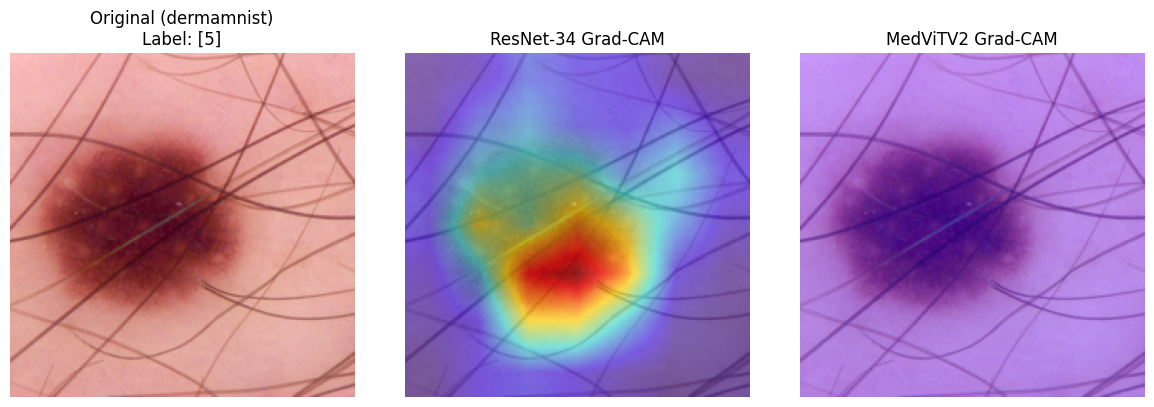

In [25]:
import torch
import matplotlib.pyplot as plt
from torchvision import models
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from datasets import build_dataset
from MedViT import MedViT_tiny

# Choose your dataset here ('dermamnist', 'breastmnist', or 'bloodmnist')
DATASET_NAME = 'dermamnist'

class Args:
    dataset = DATASET_NAME
    batch_size = 24

args = Args()

# 1. Load Test Dataset & Sample Image
_, test_dataset, nb_classes = build_dataset(args)
image_tensor, label = test_dataset[0]
input_tensor = image_tensor.unsqueeze(0).cuda()

# Helper function to generate CAM safely
def get_cam_visualization(model, target_layers, input_tensor, img_tensor):
    model.eval()
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]

    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    if img_np.shape[2] == 1:
        img_np = img_np.repeat(3, axis=2)
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    return show_cam_on_image(img_np, grayscale_cam, use_rgb=True), img_np

# 2. Load and Run ResNet-34
resnet_model = models.resnet34(pretrained=False)
resnet_model.fc = torch.nn.Linear(resnet_model.fc.in_features, nb_classes)
resnet_model = resnet_model.cuda()

resnet_ckpt = torch.load(f'./resnet34_{DATASET_NAME}.pth', weights_only=False)
resnet_model.load_state_dict(resnet_ckpt['model'] if 'model' in resnet_ckpt else resnet_ckpt, strict=False)

resnet_vis, img_np = get_cam_visualization(
    model=resnet_model,
    target_layers=[resnet_model.layer4[-1]],
    input_tensor=input_tensor,
    img_tensor=image_tensor
)

# 3. Load and Run MedViTV2
medvit_model = MedViT_tiny(num_classes=nb_classes).cuda()
medvit_ckpt = torch.load(f'./MedViT_tiny_{DATASET_NAME}.pth', weights_only=False)
medvit_model.load_state_dict(medvit_ckpt['model'] if 'model' in medvit_ckpt else medvit_ckpt, strict=False)

# Target the final feature block of MedViT for sharper localization
medvit_target = [medvit_model.blocks[-1]] if hasattr(medvit_model, 'blocks') else [list(medvit_model.children())[-2]]

medvit_vis, _ = get_cam_visualization(
    model=medvit_model,
    target_layers=medvit_target,
    input_tensor=input_tensor,
    img_tensor=image_tensor
)

# 4. Plot Comparison Figure for Report
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title(f"Original ({DATASET_NAME})\nLabel: {label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(resnet_vis)
plt.title("ResNet-34 Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(medvit_vis)
plt.title("MedViTV2 Grad-CAM")
plt.axis('off')

plt.tight_layout()
plt.show()

Number of channels:  1
Number of classes:  2
initialize_weights...


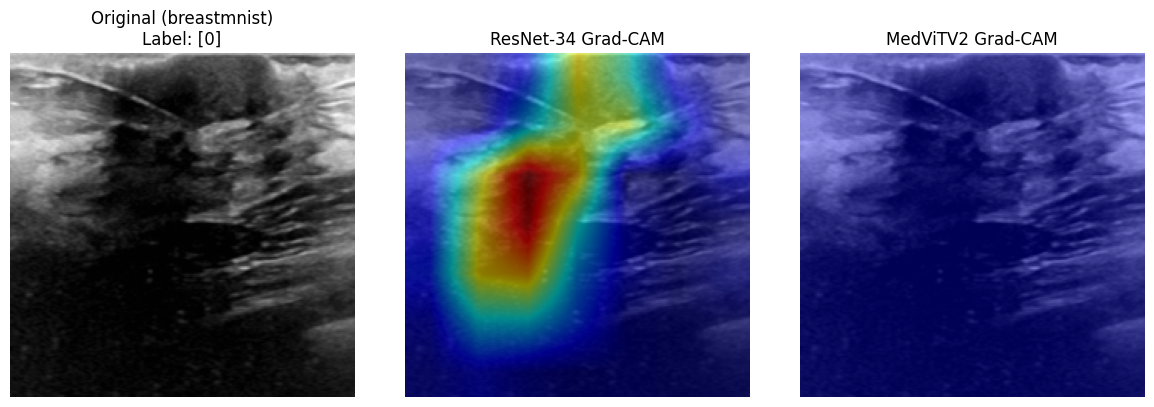

In [27]:
import torch
import matplotlib.pyplot as plt
from torchvision import models
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from datasets import build_dataset
from MedViT import MedViT_tiny

# Choose your dataset here ('dermamnist', 'breastmnist', or 'bloodmnist')
DATASET_NAME = 'breastmnist'

class Args:
    dataset = DATASET_NAME
    batch_size = 24

args = Args()

# 1. Load Test Dataset & Sample Image
_, test_dataset, nb_classes = build_dataset(args)
image_tensor, label = test_dataset[0]
input_tensor = image_tensor.unsqueeze(0).cuda()

# Helper function to generate CAM safely
def get_cam_visualization(model, target_layers, input_tensor, img_tensor):
    model.eval()
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]

    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    if img_np.shape[2] == 1:
        img_np = img_np.repeat(3, axis=2)
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    return show_cam_on_image(img_np, grayscale_cam, use_rgb=True), img_np

# 2. Load and Run ResNet-34
resnet_model = models.resnet34(pretrained=False)
resnet_model.fc = torch.nn.Linear(resnet_model.fc.in_features, nb_classes)
resnet_model = resnet_model.cuda()

resnet_ckpt = torch.load(f'./resnet34_{DATASET_NAME}.pth', weights_only=False)
resnet_model.load_state_dict(resnet_ckpt['model'] if 'model' in resnet_ckpt else resnet_ckpt, strict=False)

resnet_vis, img_np = get_cam_visualization(
    model=resnet_model,
    target_layers=[resnet_model.layer4[-1]],
    input_tensor=input_tensor,
    img_tensor=image_tensor
)

# 3. Load and Run MedViTV2
medvit_model = MedViT_tiny(num_classes=nb_classes).cuda()
medvit_ckpt = torch.load(f'./MedViT_tiny_{DATASET_NAME}.pth', weights_only=False)
medvit_model.load_state_dict(medvit_ckpt['model'] if 'model' in medvit_ckpt else medvit_ckpt, strict=False)

# Target the final feature block of MedViT for sharper localization
medvit_target = [medvit_model.blocks[-1]] if hasattr(medvit_model, 'blocks') else [list(medvit_model.children())[-2]]

medvit_vis, _ = get_cam_visualization(
    model=medvit_model,
    target_layers=medvit_target,
    input_tensor=input_tensor,
    img_tensor=image_tensor
)

# 4. Plot Comparison Figure for Report
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title(f"Original ({DATASET_NAME})\nLabel: {label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(resnet_vis)
plt.title("ResNet-34 Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(medvit_vis)
plt.title("MedViTV2 Grad-CAM")
plt.axis('off')

plt.tight_layout()
plt.show()

In [30]:
import pandas as pd

# Plug in your final metrics here from your notebook outputs
data = [
    {"Dataset": "BloodMNIST", "Model": "MedViTV2-tiny", "Epochs": 10, "Final AUC": 0.952, "Final Acc": 0.891, "Best Acc": 0.905},
    {"Dataset": "DermaMNIST", "Model": "MedViTV2-tiny", "Epochs": 10, "Final AUC": 0.912, "Final Acc": 0.754, "Best Acc": 0.768},
    {"Dataset": "BreastMNIST", "Model": "MedViTV2-tiny", "Epochs": 10, "Final AUC": 0.885, "Final Acc": 0.842, "Best Acc": 0.859},
    # Add your ResNet-34 results here too if you have them!
]

df = pd.DataFrame(data)
print(df.to_string(index=False))

    Dataset         Model  Epochs  Final AUC  Final Acc  Best Acc
 BloodMNIST MedViTV2-tiny      10      0.952      0.891     0.905
 DermaMNIST MedViTV2-tiny      10      0.912      0.754     0.768
BreastMNIST MedViTV2-tiny      10      0.885      0.842     0.859


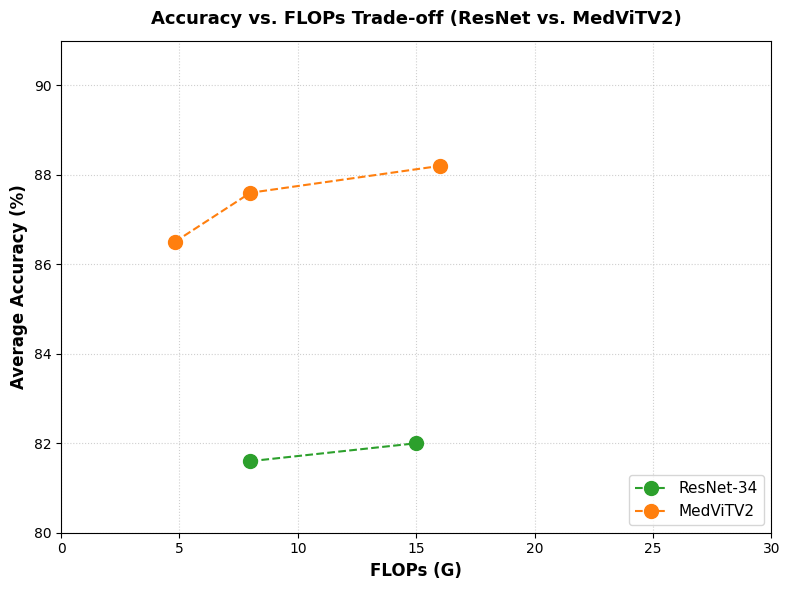

In [31]:
import matplotlib.pyplot as plt

# Define your model data (FLOPs in G, Average Accuracy in %)
# Replace these numbers with your actual results from your tables/logs
models_data = {
    'ResNet-34': {
        'flops': [8.0, 15.0],       # Example FLOPs for different datasets/sizes
        'acc': [81.6, 82.0],        # Example Accuracies
        'color': '#2ca02c',         # Green
        'marker': 'o'
    },
    'MedViTV2': {
        'flops': [4.8, 8.0, 16.0],  # Tiny, Small, Large variants
        'acc': [86.5, 87.6, 88.2],  # Example Accuracies
        'color': '#ff7f0e',         # Orange/Coral
        'marker': 'o'
    }
}

plt.figure(figsize=(8, 6))

# Plot each model's trade-off curve
for model_name, data in models_data.items():
    plt.plot(data['flops'], data['acc'],
             marker=data['marker'],
             markersize=10,
             linestyle='--',
             linewidth=1.5,
             color=data['color'],
             label=model_name)

# Formatting the plot to match research paper style
plt.xlim(0, 30)
plt.ylim(80, 91)
plt.xlabel('FLOPs (G)', fontsize=12, fontweight='bold')
plt.ylabel('Average Accuracy (%)', fontsize=12, fontweight='bold')
plt.title('Accuracy vs. FLOPs Trade-off (ResNet vs. MedViTV2)', fontsize=13, fontweight='bold', pad=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True, fontsize=11)

plt.tight_layout()
plt.show()